In [6]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from typing import TypedDict

In [11]:
load_dotenv()

True

In [12]:
class StateLLM(TypedDict):
    question:str
    answer:str

In [13]:
def qna(state:StateLLM)->StateLLM:
    llm=ChatOpenAI(model='gpt-4o')
    prompt=PromptTemplate(template="""answer the following question in 1-2 lines : QUESTION : {question}""",
                          input_variables=['question'])
    chain= prompt | llm
    response= chain.invoke({'question':state['question']}).content
    state['answer']=response
    return state

In [14]:
graph=StateGraph(StateLLM)

In [15]:
graph.add_node('qna',qna)
graph.add_edge(START,'qna')
graph.add_edge('qna',END)

In [16]:
workflow=graph.compile()

In [17]:
initial_state={'question':'who is the prime minister of india'}

In [18]:
final_state=workflow.invoke(initial_state)

In [19]:
final_state

{'question': 'who is the prime minister of india',
 'answer': 'As of my last update, the Prime Minister of India is Narendra Modi.'}

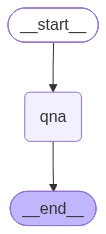

In [20]:
workflow